# $120^\circ$ Néel spin structure

## Questions

1. Why isn't $V({\bf R}) = V(-{\bf R})$?
2. More measurements? Correlation functions?

In [1]:
using Random: MersenneTwister

using MX2RKKY

Precompiling MX2RKKY
  ✓ MX2RKKY
  1 dependency successfully precompiled in 4 seconds. 24 already precompiled.


In [9]:
L1, L2 = 25, 25

# Temperature
T = 0.01
# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0
# RKKY parameters
Vpar = 0.0
Vperp = 0.0
λ = 0.05 # k_F a_0

n_cycles = 10000
n_warmup_cycles = 1000
cycle_length = 50

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)

sim = MCSimulation(conf, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)

Progress: 100%|█████████████████████████████████████████| Time: 0:03:46


In [10]:
@show acceptance_rates(sim)

@show min_energy(sim) / (L1 * L2)

@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)

@show avg_chirality(sim)
@show var_chirality(sim)

acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.UpdateTriangle => 0.0015481567827480695, MX2RKKY.UpdateSingleSpin{true} => 0.011403848950506569)
min_energy(sim) / (L1 * L2) = -1.5011802682954891
avg_energy(sim) / (L1 * L2) = -1.4440132360736226
var_energy(sim) / (L1 * L2) = 0.07923965226991729
avg_chirality(sim) = -0.004659680000000119
var_chirality(sim) = 0.01498968679784843


0.01498968679784843

In [5]:
using PyPlot; const plt = PyPlot;
plt.pygui(false); plt.svg(true);

function plot_conf(conf::MX2RKKY.Configuration, plot_scale::Float64 = 0.5)
    i2c = (i1, i2) -> (i1 - 0.5 * i2, √3/2 * i2)
    L1, L2 = size(conf)

    # Draw triangular grid
    grid_segments = []
    for i1 in 0:(L1-1)
        push!(grid_segments, [i2c(i1, 0), i2c(i1, L2-1)])
        (i1 == L1-1) && continue
        lenc = L1-i1-1
        push!(grid_segments, [i2c(i1, 0), i2c(i1, 0) .+ i2c(lenc, lenc)])
    end
    for i2 in 0:(L2-1)
        push!(grid_segments, [i2c(0, i2), i2c(L1-1, i2)])
        (i2 == 0 || i2 == L2-1) && continue
        lenc = min(L2-i2-1, L1-1)
        push!(grid_segments, [i2c(0, i2), i2c(0, i2) .+ i2c(lenc, lenc)])
    end
    grid = plt.matplotlib.collections.LineCollection(grid_segments, linewidths=0.5)

    xmin = minimum(min(s[1][1], s[2][1]) for s in grid_segments)
    xmax = maximum(max(s[1][1], s[2][1]) for s in grid_segments)
    ymin = minimum(min(s[1][2], s[2][2]) for s in grid_segments)
    ymax = maximum(max(s[1][2], s[2][2]) for s in grid_segments)
    
    fig = plt.figure(figsize=(plot_scale * (xmax-xmin), plot_scale * (ymax-ymin)))
    ax = plt.gca()
    ax.add_collection(grid)
    
    # Draw spins
    for i in eachindex(conf)
        Sx, Sy = plot_scale * conf.S_vec[1:2, i...] ./ conf.S
        x, y = i2c(i...)
        plt.arrow(x - Sx/2, y - Sy/2, Sx, Sy, color="red", head_width=0.1)
    end

    ax.set_xlim(xmin - 2 * plot_scale, xmax + 2 * plot_scale)
    ax.set_ylim(ymin - 2 * plot_scale, ymax + 2 * plot_scale)
    plt.show()
end

plot_conf (generic function with 2 methods)

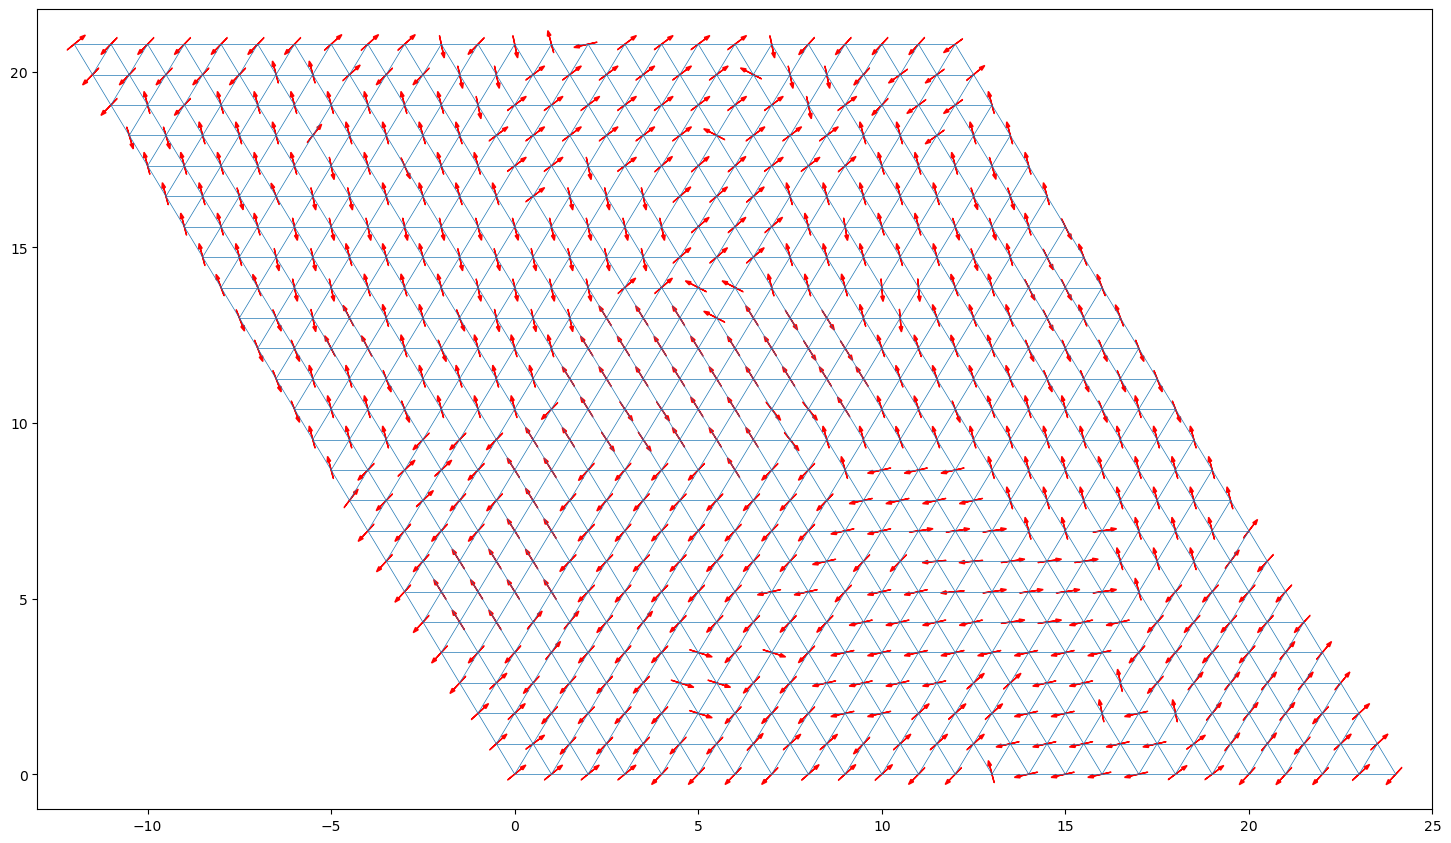

In [12]:
plot_conf(sim.conf)